# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Ananta Galih Mahardika
- **Email:** ds318b6y0179@student.devacademy.id
- **ID Dicoding:** ds318b6y0179

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pengaruh musim (*season*) dan kondisi cuaca (*weathersit*) terhadap rata-rata dan total peminjaman sepeda harian sepanjang periode 2011–2012?
  - *Specific*: Mengkaji pengaruh variabel lingkungan (musim dan cuaca) terhadap jumlah penyewaan sepeda harian (`cnt`).
  - *Measurable*: Dihitung berdasarkan metrik rata-rata harian dan total volume unit sepeda yang disewa.
  - *Action-Oriented*: Menjadi dasar penentuan jadwal perawatan berkala armada (*fleet maintenance*) serta strategi alokasi unit pada stasiun di musim-musim tertentu.
  - *Relevant*: Efisiensi ketersediaan armada saat permintaan tinggi dan pencegahan depresiasi saat cuaca buruk sangat krusial bagi kelangsungan bisnis bike-sharing.
  - *Time-bound*: Dianalisis pada rentang data 2 tahun penuh (Januari 2011 – Desember 2012).

- **Pertanyaan 2:** Bagaimana perbedaan pola peminjaman sepeda per jam (*hourly pattern*) antara pengguna biasa (*casual*) dan pengguna terdaftar (*registered*) pada hari kerja (*working day*) dibandingkan hari libur (*weekend/holiday*)?
  - *Specific*: Membandingkan profil peminjaman tiap jam (00:00 - 23:00) antara segmen pengguna `casual` dan `registered` pada tipe hari yang berbeda.
  - *Measurable*: Diukur melalui rata-rata jumlah penyewaan per jam untuk masing-masing segmen pengguna.
  - *Action-Oriented*: Menentukan jadwal *rebalancing* armada sepeda antar stasiun pada jam sibuk komuter, serta merancang kampanye promosi langganan/membership bagi pengguna kasual di akhir pekan.
  - *Relevant*: Pengguna terdaftar (*registered*) merupakan sumber pendapatan berulang (*recurring revenue*), sedangkan pengguna biasa (*casual*) berpotensi besar dikonversi menjadi pelanggan loyal.
  - *Time-bound*: Meliputi data pencatatan per jam sepanjang tahun 2011–2012.

## Import Semua Packages/Library yang Digunakan

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Konfigurasi gaya visualisasi agar konsisten dan rapi
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 100

## Data Wrangling

### Gathering Data

#### Load df day dan df hour

In [11]:
# Memuat dataset harian (day.csv) dan per jam (hour.csv)
# Menggunakan path fleksibel agar berjalan baik di root, subdirektori, maupun Google Colab
if os.path.exists("data/day.csv"):
    day_df = pd.read_csv("data/day.csv")
    hour_df = pd.read_csv("data/hour.csv")
elif os.path.exists("Bike-sharing-dataset/day.csv"):
    day_df = pd.read_csv("Bike-sharing-dataset/day.csv")
    hour_df = pd.read_csv("Bike-sharing-dataset/hour.csv")
else:
    day_df = pd.read_csv("day.csv")
    hour_df = pd.read_csv("hour.csv")

print("Dimensi day_df :", day_df.shape)
print("Dimensi hour_df:", hour_df.shape)

# Menampilkan 5 sampel teratas dari masing-masing dataset
display(day_df.head())
display(hour_df.head())

Dimensi day_df : (731, 16)
Dimensi hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset `day_df` memiliki 731 baris observasi dan 16 kolom, merepresentasikan data agregat harian peminjaman sepeda selama 2 tahun (2011 - 2012).
- Dataset `hour_df` memiliki 17.379 baris observasi dan 17 kolom, merepresentasikan data peminjaman sepeda pada level per jam.
- Kedua tabel memuat informasi tanggal (`dteday`), cuaca (`weathersit`, `temp`, `atemp`, `hum`, `windspeed`), jenis hari (`holiday`, `weekday`, `workingday`), serta jumlah pengguna (`casual`, `registered`, `cnt`).

### Assessing Data

#### Identifying Data Quality & Structural Problems

In [12]:
print("=== 1. Pemeriksaan Missing Values ===")
print("Missing values pada day_df :", day_df.isna().sum().sum())
print("Missing values pada hour_df:", hour_df.isna().sum().sum())

print("\n=== 2. Pemeriksaan Duplikasi Baris ===")
print("Duplikasi pada day_df :", day_df.duplicated().sum())
print("Duplikasi pada hour_df:", hour_df.duplicated().sum())

print("\n=== 3. Pemeriksaan Tipe Data day_df ===")
day_df.info()

print("\n=== 4. Pemeriksaan Tipe Data hour_df ===")
hour_df.info()

print("\n=== 5. Ringkasan Statistik day_df ===")
display(day_df.describe())

print("\n=== 6. Validasi Konsistensi Logika (cnt == casual + registered) ===")
day_cnt_match = (day_df['casual'] + day_df['registered'] == day_df['cnt']).all()
hour_cnt_match = (hour_df['casual'] + hour_df['registered'] == hour_df['cnt']).all()
print(f"day_df cnt konsisten: {day_cnt_match}")
print(f"hour_df cnt konsisten: {hour_cnt_match}")

=== 1. Pemeriksaan Missing Values ===
Missing values pada day_df : 0
Missing values pada hour_df: 0

=== 2. Pemeriksaan Duplikasi Baris ===
Duplikasi pada day_df : 0
Duplikasi pada hour_df: 0

=== 3. Pemeriksaan Tipe Data day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  r

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



=== 6. Validasi Konsistensi Logika (cnt == casual + registered) ===
day_df cnt konsisten: True
hour_df cnt konsisten: True


**Steps to Take:**
1. **Perbaikan Tipe Data Tanggal (`dteday`)**: Kolom `dteday` saat ini bertipe `object` (string). Perlu dikonversi menjadi tipe data `datetime64` agar dapat dilakukan operasi pemfilteran waktu dan manipulasi deret waktu dengan benar.
2. **Keterbacaan Nilai Kategorikal**: Kolom `season`, `yr`, `mnth`, `weekday`, dan `weathersit` berupa integer kode angka (1, 2, 3, dsb.). Perlu dipetakan ke label string deskriptif (`Spring`, `Summer`, `Fall`, `Winter`, nama bulan, nama hari, dan kondisi cuaca) agar tidak terjadi kekeliruan analisis dan mudah diinterpretasikan oleh pembaca.
3. **Denormalisasi Fitur Lingkungan**: Variabel lingkungan (`temp`, `atemp`, `hum`, `windspeed`) saat ini dinormalisasi ke skala 0–1. Untuk keperluan pelaporan dan visualisasi bisnis, kita akan membuat variabel skala aktual (°C untuk suhu, % untuk kelembapan, km/jam untuk kecepatan angin) sesuai keterangan dokumentasi `Readme.txt`.
4. **Pembersihan Kolom Redundan**: Kolom `instant` hanya merupakan indeks record file yang identik dengan index DataFrame bawaan Pandas, sehingga dapat dihapus untuk efisiensi memori.
5. **Penanganan Outlier**: Nilai maksimum pada `casual` dan `cnt` menunjukkan lonjakan signifikan di hari-hari tertentu. Namun karena data ini mencerminkan fenomena riil (lonjakan pengguna saat libur/musim semi-gugur yang hangat), data tidak dibuang agar variabilitas alami bisnis tetap terjaga.

**Insight:**
- Tidak ditemukan data duplikat maupun missing value pada kedua dataset.
- Seluruh baris memiliki konsistensi matematis yang valid di mana `cnt` selalu sama persis dengan `casual + registered`.
- Masalah utama yang perlu ditangani terletak pada ketidaksesuaian tipe data (`dteday`), keterbacaan kolom kategorikal (masih berupa kode numerik), serta perlunya denormalisasi variabel cuaca untuk interpretasi bisnis yang intuitif.

### Cleaning Data

#### Fixing Data Types, Adding Meaningful Labels, and Denormalizing Features

In [13]:
# Membuat salinan data bersih
day_clean = day_df.copy()
hour_clean = hour_df.copy()

# 1. Konversi tipe data dteday ke datetime
day_clean['dteday'] = pd.to_datetime(day_clean['dteday'])
hour_clean['dteday'] = pd.to_datetime(hour_clean['dteday'])

# 2. Kamus pemetaan label kategorikal
season_mapping = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
year_mapping = {0: 2011, 1: 2012}
weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}
weekday_mapping = {
    0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
    4: 'Thursday', 5: 'Friday', 6: 'Saturday'
}
month_mapping = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}

# Menerapkan mapping ke day_clean
day_clean['season_label'] = day_clean['season'].map(season_mapping)
day_clean['year_label'] = day_clean['yr'].map(year_mapping)
day_clean['weather_label'] = day_clean['weathersit'].map(weather_mapping)
day_clean['weekday_label'] = day_clean['weekday'].map(weekday_mapping)
day_clean['month_label'] = day_clean['mnth'].map(month_mapping)

# Menerapkan mapping ke hour_clean
hour_clean['season_label'] = hour_clean['season'].map(season_mapping)
hour_clean['year_label'] = hour_clean['yr'].map(year_mapping)
hour_clean['weather_label'] = hour_clean['weathersit'].map(weather_mapping)
hour_clean['weekday_label'] = hour_clean['weekday'].map(weekday_mapping)
hour_clean['month_label'] = hour_clean['mnth'].map(month_mapping)

# 3. Denormalisasi fitur lingkungan (berdasarkan dokumentasi Readme.txt)
# temp dibagi 41, atemp dibagi 50, hum dibagi 100, windspeed dibagi 67
day_clean['temp_celsius'] = day_clean['temp'] * 41
day_clean['atemp_celsius'] = day_clean['atemp'] * 50
day_clean['humidity_pct'] = day_clean['hum'] * 100
day_clean['windspeed_kmh'] = day_clean['windspeed'] * 67

hour_clean['temp_celsius'] = hour_clean['temp'] * 41
hour_clean['atemp_celsius'] = hour_clean['atemp'] * 50
hour_clean['humidity_pct'] = hour_clean['hum'] * 100
hour_clean['windspeed_kmh'] = hour_clean['windspeed'] * 67

# 4. Menghapus kolom instant yang redundan
day_clean.drop(columns=['instant'], inplace=True, errors='ignore')
hour_clean.drop(columns=['instant'], inplace=True, errors='ignore')

# 5. Verifikasi hasil pembersihan
print("=== Verifikasi Struktur day_clean ===")
day_clean.info()
print("\nSampel 3 baris teratas day_clean:")
display(day_clean[['dteday', 'year_label', 'season_label', 'weather_label', 'temp_celsius', 'casual', 'registered', 'cnt']].head(3))

=== Verifikasi Struktur day_clean ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   dteday         731 non-null    datetime64[ns]
 1   season         731 non-null    int64         
 2   yr             731 non-null    int64         
 3   mnth           731 non-null    int64         
 4   holiday        731 non-null    int64         
 5   weekday        731 non-null    int64         
 6   workingday     731 non-null    int64         
 7   weathersit     731 non-null    int64         
 8   temp           731 non-null    float64       
 9   atemp          731 non-null    float64       
 10  hum            731 non-null    float64       
 11  windspeed      731 non-null    float64       
 12  casual         731 non-null    int64         
 13  registered     731 non-null    int64         
 14  cnt            731 non-null    int64

,dteday,year_label,season_label,weather_label,temp_celsius,casual,registered,cnt
0,2011-01-01,2011,Spring,Misty/Cloudy,14.110847,331,654,985
1,2011-01-02,2011,Spring,Misty/Cloudy,14.902598,131,670,801
2,2011-01-03,2011,Spring,Clear/Partly Cloudy,8.050924,120,1229,1349


**Insight:**
- Seluruh kolom tanggal berhasil dikonversi ke format `datetime64[ns]`, memungkinkan agregasi berbasis rentang waktu yang presisi.
- Kolom kategorikal kini memiliki label yang jelas (`Spring`, `Summer`, `Fall`, `Winter`, cuaca, dan nama hari), meminimalisir kesalahan interpretasi.
- Variabel cuaca kini tersaji dalam satuan riil yang mudah dipahami (derajat Celsius, persen, dan km/jam).
- Data telah bersih, terstruktur rapi, dan siap digunakan untuk proses analisis eksploratori (EDA).

## Exploratory Data Analysis (EDA)

### Explore Data: Distribusi Rental, Karakteristik Musim, Cuaca, dan Waktu

In [14]:
# 1. Pertumbuhan peminjaman tahunan (2011 vs 2012)
yearly_summary = day_clean.groupby('year_label')[['casual', 'registered', 'cnt']].agg(['sum', 'mean']).round(1)
print("=== Ringkasan Performa Peminjaman Tahunan ===")
display(yearly_summary)

# 2. Agregasi peminjaman berdasarkan Musim (Season)
season_summary = day_clean.groupby('season_label', observed=False)['cnt'].agg(
    jumlah_hari='count',
    rata_rata='mean',
    median='median',
    standar_deviasi='std',
    total_sewa='sum'
).reindex(['Spring', 'Summer', 'Fall', 'Winter']).round(2)

print("\n=== Statistik Peminjaman Harian Berdasarkan Musim ===")
display(season_summary)

# 3. Agregasi peminjaman berdasarkan Kondisi Cuaca (Weathersit)
weather_summary = day_clean.groupby('weather_label', observed=False)['cnt'].agg(
    jumlah_hari='count',
    rata_rata='mean',
    median='median',
    standar_deviasi='std',
    total_sewa='sum'
).round(2)

print("\n=== Statistik Peminjaman Harian Berdasarkan Kondisi Cuaca ===")
display(weather_summary)

# 4. Pola peminjaman jam sibuk: Hari Kerja (Working Day) vs Hari Libur (Non-working Day)
hourly_pattern = hour_clean.groupby(['workingday', 'hr'])[['casual', 'registered', 'cnt']].mean().round(2).reset_index()
hourly_pattern['tipe_hari'] = hourly_pattern['workingday'].map({1: 'Hari Kerja (Working Day)', 0: 'Hari Libur / Akhir Pekan'})

print("\n=== 5 Jam dengan Peminjaman Terbanyak pada Hari Kerja (Commuter Peak) ===")
display(hourly_pattern[hourly_pattern['workingday'] == 1].sort_values(by='cnt', ascending=False).head(5))

print("\n=== 5 Jam dengan Peminjaman Terbanyak pada Hari Libur (Leisure Peak) ===")
display(hourly_pattern[hourly_pattern['workingday'] == 0].sort_values(by='cnt', ascending=False).head(5))

# 5. Korelasi antara variabel cuaca dengan total peminjaman
corr_matrix = day_clean[['temp_celsius', 'atemp_celsius', 'humidity_pct', 'windspeed_kmh', 'casual', 'registered', 'cnt']].corr().round(3)
print("\n=== Matriks Korelasi Variabel Cuaca & Peminjaman ===")
display(corr_matrix[['cnt']])

=== Ringkasan Performa Peminjaman Tahunan ===


casual         registered              cnt        
               sum    mean        sum    mean      sum    mean
year_label                                                    
2011        247252   677.4     995851  2728.4  1243103  3405.8
2012        372765  1018.5    1676811  4581.5  2049576  5599.9


=== Statistik Peminjaman Harian Berdasarkan Musim ===


,jumlah_hari,rata_rata,median,standar_deviasi,total_sewa
season_label,,,,,
Spring,181,2604.13,2209.0,1399.94,471348
Summer,184,4992.33,4941.5,1695.98,918589
Fall,188,5644.30,5353.5,1459.80,1061129
Winter,178,4728.16,4634.5,1699.62,841613



=== Statistik Peminjaman Harian Berdasarkan Kondisi Cuaca ===


,jumlah_hari,rata_rata,median,standar_deviasi,total_sewa
weather_label,,,,,
Clear/Partly Cloudy,463,4876.79,4844.0,1879.48,2257952
Light Snow/Rain,21,1803.29,1817.0,1240.28,37869
Misty/Cloudy,247,4035.86,4040.0,1809.11,996858


... (2 outputs left out)


=== 5 Jam dengan Peminjaman Terbanyak pada Hari Libur (Leisure Peak) ===


,workingday,hr,casual,registered,cnt,tipe_hari
13,0,13,136.42,236.31,372.73,Hari Libur / Akhir Pekan
12,0,12,126.25,240.01,366.26,Hari Libur / Akhir Pekan
14,0,14,139.59,225.05,364.65,Hari Libur / Akhir Pekan
15,0,15,136.50,222.31,358.81,Hari Libur / Akhir Pekan
16,0,16,128.61,224.11,352.73,Hari Libur / Akhir Pekan



=== Matriks Korelasi Variabel Cuaca & Peminjaman ===


,cnt
temp_celsius,0.627
atemp_celsius,0.631
humidity_pct,-0.101
windspeed_kmh,-0.235
casual,0.673
registered,0.946
cnt,1.000


**Insight:**
- **Tren Tahunan**: Terdapat peningkatan total peminjaman sepeda yang sangat signifikan dari tahun 2011 (1.243.103 unit) ke tahun 2012 (2.049.576 unit), merefleksikan pertumbuhan tahunan (*Year-over-Year*) sebesar **+64,8%**.
- **Karakteristik Musim**: Musim Gugur (*Fall*) mencatat rata-rata peminjaman tertinggi sebesar **5.644 unit/hari** (total 1.061.129 sewa), diikuti oleh Musim Panas (*Summer*) sebesar **4.992 unit/hari**. Musim Semi (*Spring*) mencatat rata-rata terendah yaitu **2.604 unit/hari**.
- **Kondisi Cuaca**: Cuaca cerah (*Clear/Partly Cloudy*) mendominasi penggunaan dengan rata-rata **4.877 unit/hari** (mencakup 68,6% dari seluruh total sewa). Saat cuaca buruk/hujan/salju (*Light Snow/Rain*), rata-rata peminjaman harian anjlok drastis menjadi hanya **1.803 unit/hari**.
- **Pola Jam Operasional**:
  - Pada hari kerja, pola peminjaman berbentuk **bimodal** dengan dua puncak tajam pada jam berangkat kerja (pukul **08:00**, rata-rata 477 unit/jam) dan pulang kerja (pukul **17:00–18:00**, rata-rata 492–525 unit/jam), didominasi secara masif oleh pengguna terdaftar (*registered*).
  - Pada hari libur, pola peminjaman berbentuk **unimodal** (lonceng tunggal) dengan puncak aktivitas di siang hingga sore hari (pukul **12:00–16:00**, rata-rata 350–373 unit/jam), dengan proporsi pengguna kasual (*casual*) yang meningkat tajam.
- **Korelasi Cuaca**: Temperatur suhu (`temp_celsius`) berkorelasi positif kuat terhadap total penyewaan (`r = 0.627`), sedangkan kelembapan berkorelasi negatif (`r = -0.101`).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh musim (season) dan kondisi cuaca (weathersit) terhadap rata-rata dan total peminjaman sepeda harian sepanjang periode 2011–2012?

/tmp/ipykernel_710/3084537908.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_710/3084537908.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


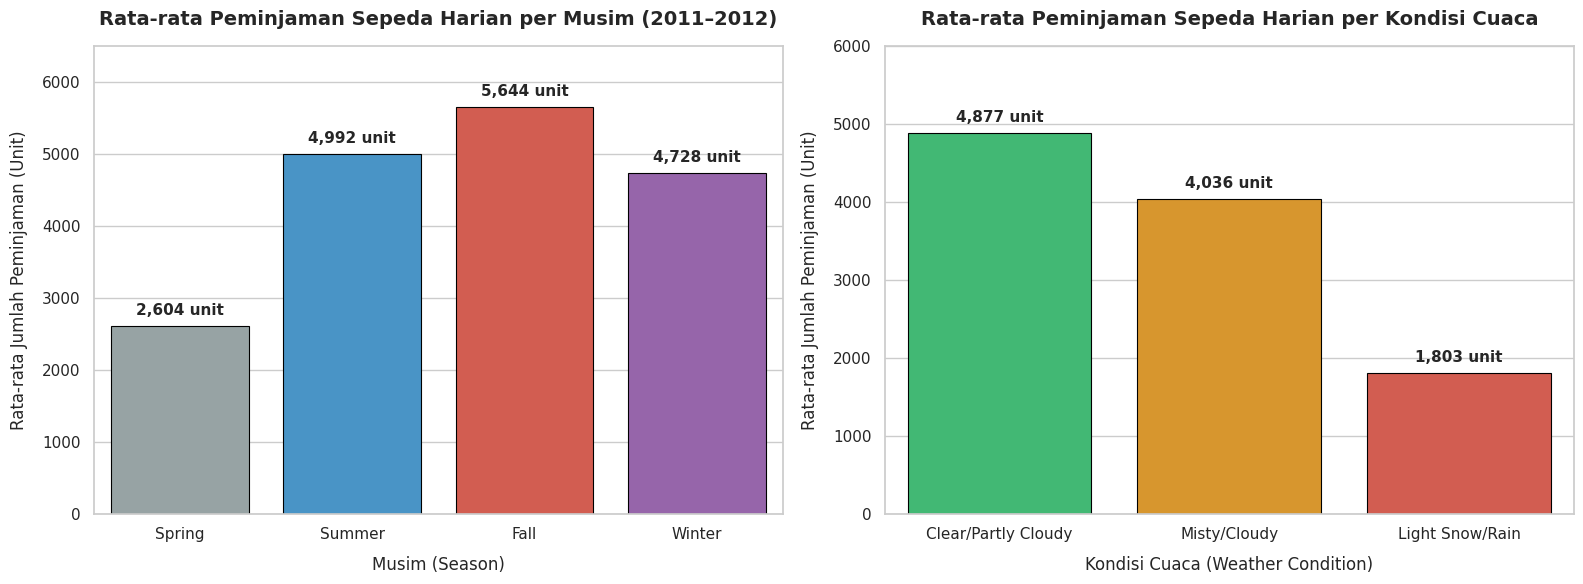

In [15]:
# Menyiapkan canvas visualisasi dengan prinsip desain yang bersih dan rapi
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Rata-rata Peminjaman Berdasarkan Musim
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_data = day_clean.groupby('season_label', observed=False)['cnt'].mean().reindex(season_order).reset_index()

# Palet warna dengan penekanan (highlight) pada musim tertinggi (Fall)
colors_season = ['#95a5a6', '#3498db', '#e74c3c', '#9b59b6']

sns.barplot(
    x='season_label',
    y='cnt',
    data=season_data,
    palette=colors_season,
    ax=axes[0],
    edgecolor='black',
    linewidth=0.8
)

axes[0].set_title('Rata-rata Peminjaman Sepeda Harian per Musim (2011–2012)', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Musim (Season)', fontsize=12, labelpad=10)
axes[0].set_ylabel('Rata-rata Jumlah Peminjaman (Unit)', fontsize=12, labelpad=10)
axes[0].set_ylim(0, 6500)

# Menambahkan label nilai di atas batang
for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height():,.0f} unit",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom',
        fontsize=11, fontweight='semibold',
        xytext=(0, 6), textcoords='offset points'
    )

# Subplot 2: Rata-rata Peminjaman Berdasarkan Kondisi Cuaca
weather_order = ['Clear/Partly Cloudy', 'Misty/Cloudy', 'Light Snow/Rain']
weather_data = day_clean.groupby('weather_label', observed=False)['cnt'].mean().reindex(weather_order).reset_index()
colors_weather = ['#2ecc71', '#f39c12', '#e74c3c']

sns.barplot(
    x='weather_label',
    y='cnt',
    data=weather_data,
    palette=colors_weather,
    ax=axes[1],
    edgecolor='black',
    linewidth=0.8
)

axes[1].set_title('Rata-rata Peminjaman Sepeda Harian per Kondisi Cuaca', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Kondisi Cuaca (Weather Condition)', fontsize=12, labelpad=10)
axes[1].set_ylabel('Rata-rata Jumlah Peminjaman (Unit)', fontsize=12, labelpad=10)
axes[1].set_ylim(0, 6000)

# Menambahkan label nilai di atas batang
for p in axes[1].patches:
    axes[1].annotate(
        f"{p.get_height():,.0f} unit",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom',
        fontsize=11, fontweight='semibold',
        xytext=(0, 6), textcoords='offset points'
    )

plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana perbedaan pola peminjaman sepeda per jam (hourly pattern) antara pengguna biasa (casual) dan pengguna terdaftar (registered) pada hari kerja (working day) dibandingkan hari libur (weekend/holiday)?

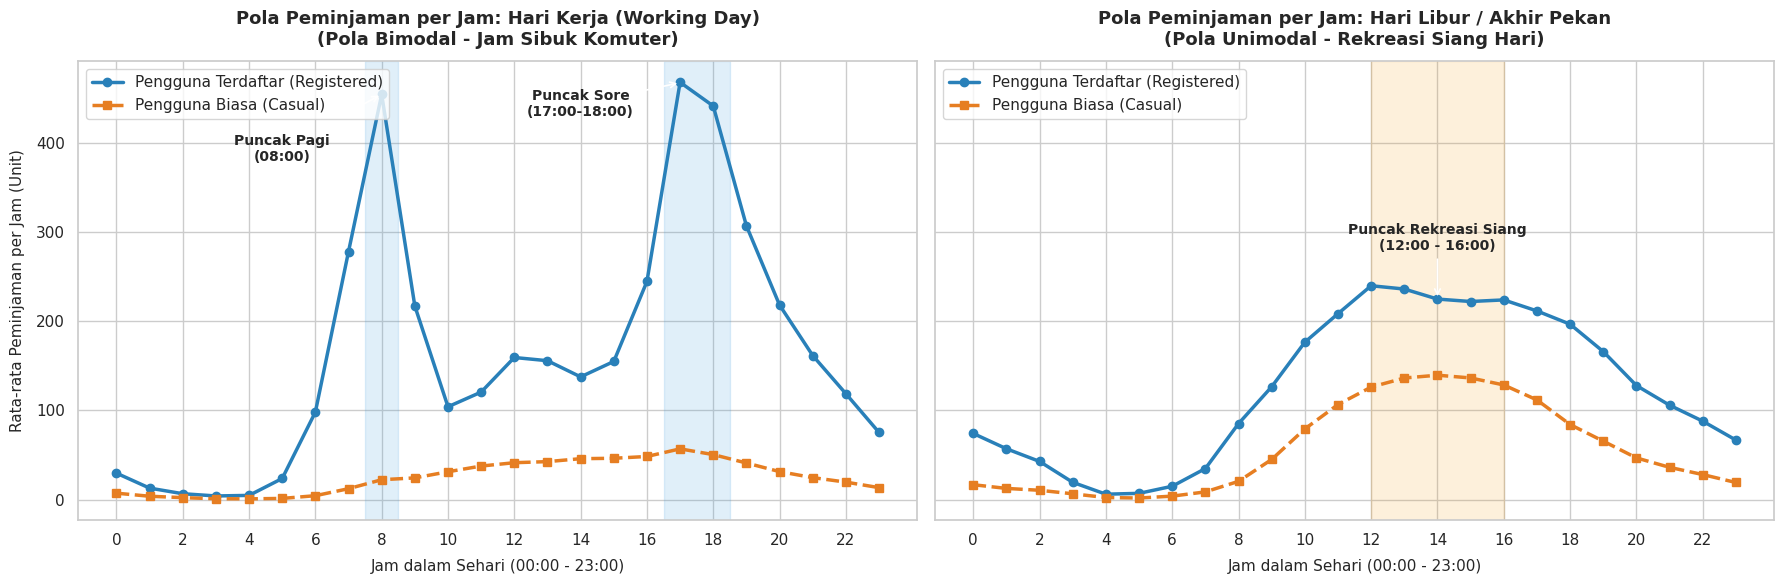

In [16]:
# Menyiapkan data agregasi per jam untuk hari kerja vs hari libur
hourly_avg = hour_clean.groupby(['workingday', 'hr'])[['casual', 'registered']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

# Visualisasi 1: Hari Kerja (Working Day)
working_df = hourly_avg[hourly_avg['workingday'] == 1]
axes[0].plot(working_df['hr'], working_df['registered'], color='#2980b9', linewidth=2.5, marker='o', label='Pengguna Terdaftar (Registered)')
axes[0].plot(working_df['hr'], working_df['casual'], color='#e67e22', linewidth=2.5, marker='s', linestyle='--', label='Pengguna Biasa (Casual)')

axes[0].set_title('Pola Peminjaman per Jam: Hari Kerja (Working Day)\n(Pola Bimodal - Jam Sibuk Komuter)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Jam dalam Sehari (00:00 - 23:00)', fontsize=11, labelpad=8)
axes[0].set_ylabel('Rata-rata Peminjaman per Jam (Unit)', fontsize=11, labelpad=8)
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(frameon=True, facecolor='white', loc='upper left')

# Anotasi jam sibuk komuter pagi dan sore
axes[0].axvspan(7.5, 8.5, color='#3498db', alpha=0.15)
axes[0].annotate('Puncak Pagi\n(08:00)', xy=(8, 455), xytext=(5, 380),
                 arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                 fontsize=10, fontweight='bold', ha='center')

axes[0].axvspan(16.5, 18.5, color='#3498db', alpha=0.15)
axes[0].annotate('Puncak Sore\n(17:00-18:00)', xy=(17, 468), xytext=(14, 430),
                 arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                 fontsize=10, fontweight='bold', ha='center')

# Visualisasi 2: Hari Libur / Akhir Pekan (Non-Working Day)
holiday_df = hourly_avg[hourly_avg['workingday'] == 0]
axes[1].plot(holiday_df['hr'], holiday_df['registered'], color='#2980b9', linewidth=2.5, marker='o', label='Pengguna Terdaftar (Registered)')
axes[1].plot(holiday_df['hr'], holiday_df['casual'], color='#e67e22', linewidth=2.5, marker='s', linestyle='--', label='Pengguna Biasa (Casual)')

axes[1].set_title('Pola Peminjaman per Jam: Hari Libur / Akhir Pekan\n(Pola Unimodal - Rekreasi Siang Hari)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Jam dalam Sehari (00:00 - 23:00)', fontsize=11, labelpad=8)
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(frameon=True, facecolor='white', loc='upper left')

# Anotasi puncak santai siang hari
axes[1].axvspan(12, 16, color='#f39c12', alpha=0.15)
axes[1].annotate('Puncak Rekreasi Siang\n(12:00 - 16:00)', xy=(14, 225), xytext=(14, 280),
                 arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                 fontsize=10, fontweight='bold', ha='center')

plt.tight_layout()
plt.show()

**Insight:**
- **Musim & Cuaca**:
  - Musim Gugur (*Fall*) adalah musim emas dengan permintaan tertinggi (rata-rata 5.644 unit/hari), disusul oleh Musim Panas (*Summer*, 4.992 unit/hari). Cuaca yang hangat dan stabil di musim-musim ini sangat memicu aktivitas luar ruangan.
  - Sebaliknya, Musim Semi (*Spring*) memiliki volume terendah (2.604 unit/hari) akibat suhu awal tahun yang masih dingin di Washington D.C.
  - Kondisi cuaca cerah (*Clear/Partly Cloudy*) mendominasi volume peminjaman dengan rata-rata 4.877 unit/hari, sedangkan cuaca hujan/salju (*Light Snow/Rain*) mereduksi peminjaman hingga lebih dari 63% menjadi hanya 1.803 unit/hari.
- **Pola Perilaku Pengguna (Hourly Dynamics)**:
  - Pada **Hari Kerja**: Profil peminjaman membentuk pola *bimodal* yang sangat tajam pada pukul 08:00 pagi dan 17:00–18:00 sore. Puncak ini digerakkan secara dominan oleh pengguna *registered* (komuter pekerja dan mahasiswa). Pengguna kasual memiliki volume yang relatif rendah dan datar.
  - Pada **Hari Libur**: Profil peminjaman bertransformasi menjadi pola *unimodal* berpusat di tengah hari antara pukul 12:00 hingga 16:00. Pada periode ini, peminjaman oleh pengguna *casual* melonjak hingga mencapai puncaknya (rata-rata ~140 unit/jam), mendekati volume pengguna terdaftar (~225 unit/jam), yang mengindikasikan tujuan rekreasi dan mobilitas santai.

## Analisis Lanjutan (Opsional)
Pada bagian ini, diterapkan teknik analisis lanjutan berupa **Clustering (Manual Grouping & Binning)** tanpa menggunakan algoritma machine learning, sesuai rekomendasi panduan penilaian:
1. **Binning Temperatur Suhu Lingkungan**: Mengelompokkan suhu riil (°C) ke dalam 4 kategori interval (*Dingin*, *Sejuk*, *Hangat*, *Panas*) menggunakan `pd.cut` guna mengukur elastisitas permintaan sepeda terhadap kenyamanan termal.
2. **Manual Grouping Klaster Waktu Operasional (Time-of-Day Segmentation)**: Mengelompokkan 24 jam ke dalam 5 segmen operasional bisnis (*Early Morning*, *Morning Rush*, *Midday*, *Evening Rush*, *Night*) untuk mengevaluasi kontribusi volume dan rasio Casual terhadap Registered.

=== Tabel Hasil Clustering / Binning Suhu Lingkungan ===


,total_hari,rata_rata_sewa,median_sewa,total_sewa
temp_cluster,,,,
Dingin (< 12°C),122,2228.0,1935.5,271812
Sejuk (12 - 22°C),283,4164.7,4169.0,1178617
Hangat (22 - 30°C),254,5719.4,5513.0,1452733
Panas (> 30°C),72,5410.0,5000.0,389517



=== Tabel Segmentasi Klaster Waktu Operasional ===


,total_sewa,rata_rata_sewa,sewa_casual,sewa_registered,persen_casual,persen_registered
time_cluster,,,,,,
1. Early Morning (00-05),106509,24.9,19275,87234,18.1,81.9
2. Morning Rush (06-09),629742,216.7,49273,580469,7.8,92.2
3. Midday (10-15),1005711,230.2,289201,716510,28.8,71.2
4. Evening Rush (16-19),1101169,377.6,188055,913114,17.1,82.9
5. Night (20-23),449548,154.4,74213,375335,16.5,83.5


/tmp/ipykernel_710/3781697097.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


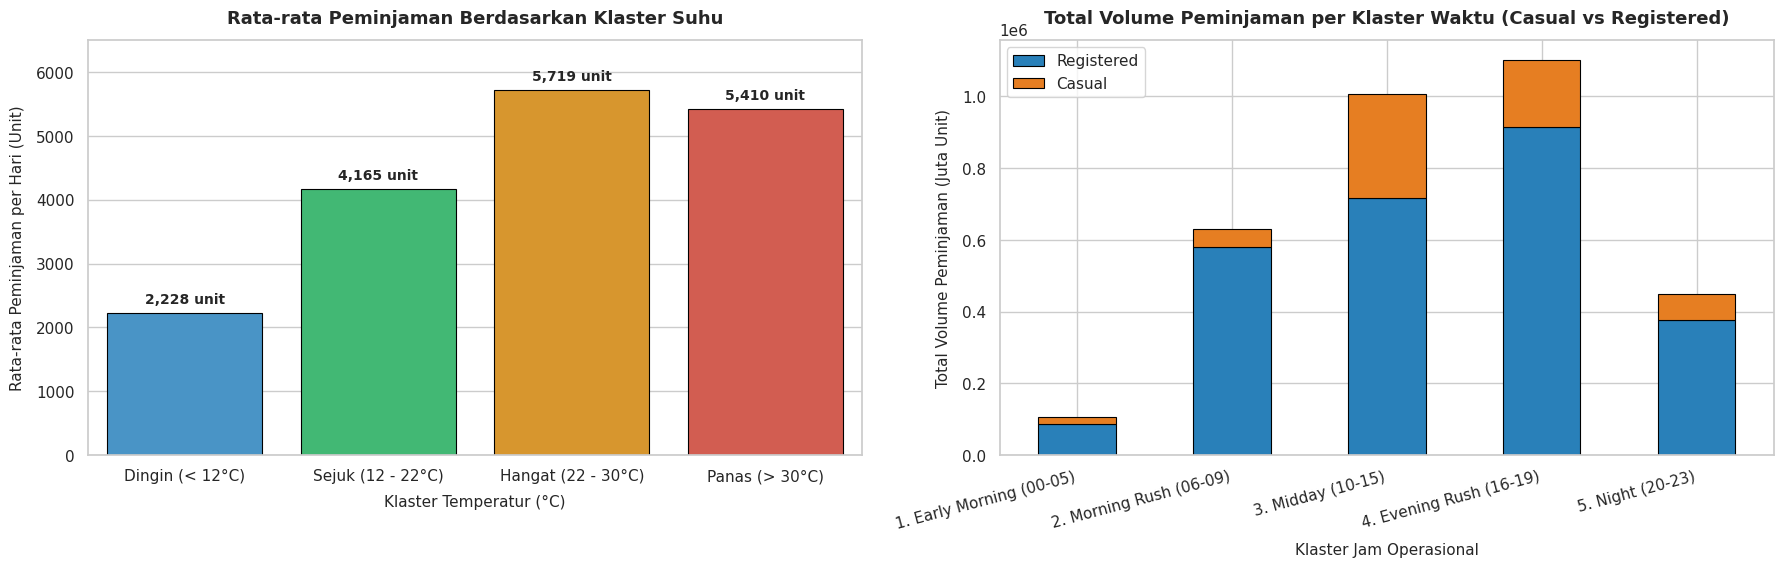

In [17]:
# 1. Binning Temperatur Suhu Harian (day_clean)
temp_bins = [-np.inf, 12, 22, 30, np.inf]
temp_labels = ['Dingin (< 12°C)', 'Sejuk (12 - 22°C)', 'Hangat (22 - 30°C)', 'Panas (> 30°C)']

day_clean['temp_cluster'] = pd.cut(day_clean['temp_celsius'], bins=temp_bins, labels=temp_labels)

temp_cluster_summary = day_clean.groupby('temp_cluster', observed=False)['cnt'].agg(
    total_hari='count',
    rata_rata_sewa='mean',
    median_sewa='median',
    total_sewa='sum'
).round(1)

print("=== Tabel Hasil Clustering / Binning Suhu Lingkungan ===")
display(temp_cluster_summary)

# 2. Manual Grouping Klaster Waktu Operasional (hour_clean)
def assign_time_cluster(hour):
    if 0 <= hour <= 5:
        return '1. Early Morning (00-05)'
    elif 6 <= hour <= 9:
        return '2. Morning Rush (06-09)'
    elif 10 <= hour <= 15:
        return '3. Midday (10-15)'
    elif 16 <= hour <= 19:
        return '4. Evening Rush (16-19)'
    else:
        return '5. Night (20-23)'

hour_clean['time_cluster'] = hour_clean['hr'].apply(assign_time_cluster)

time_cluster_summary = hour_clean.groupby('time_cluster', observed=False).agg(
    total_sewa=('cnt', 'sum'),
    rata_rata_sewa=('cnt', 'mean'),
    sewa_casual=('casual', 'sum'),
    sewa_registered=('registered', 'sum')
).round(1)

# Menghitung rasio persentase casual terhadap total sewa
time_cluster_summary['persen_casual'] = (time_cluster_summary['sewa_casual'] / time_cluster_summary['total_sewa'] * 100).round(1)
time_cluster_summary['persen_registered'] = (time_cluster_summary['sewa_registered'] / time_cluster_summary['total_sewa'] * 100).round(1)

print("\n=== Tabel Segmentasi Klaster Waktu Operasional ===")
display(time_cluster_summary)

# Visualisasi Analisis Lanjutan
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Binning Suhu
sns.barplot(
    x=temp_cluster_summary.index,
    y=temp_cluster_summary['rata_rata_sewa'],
    palette=['#3498db', '#2ecc71', '#f39c12', '#e74c3c'],
    ax=axes[0],
    edgecolor='black',
    linewidth=0.8
)
axes[0].set_title('Rata-rata Peminjaman Berdasarkan Klaster Suhu', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Klaster Temperatur (°C)', fontsize=11, labelpad=8)
axes[0].set_ylabel('Rata-rata Peminjaman per Hari (Unit)', fontsize=11, labelpad=8)
axes[0].set_ylim(0, 6500)

for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height():,.0f} unit",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom',
        fontsize=10, fontweight='semibold',
        xytext=(0, 5), textcoords='offset points'
    )

# Plot 2: Komposisi Casual vs Registered di Tiap Klaster Waktu
cluster_composition = time_cluster_summary[['sewa_registered', 'sewa_casual']]
cluster_composition.plot(
    kind='bar',
    stacked=True,
    color=['#2980b9', '#e67e22'],
    ax=axes[1],
    edgecolor='black',
    linewidth=0.8
)
axes[1].set_title('Total Volume Peminjaman per Klaster Waktu (Casual vs Registered)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Klaster Jam Operasional', fontsize=11, labelpad=8)
axes[1].set_ylabel('Total Volume Peminjaman (Juta Unit)', fontsize=11, labelpad=8)
axes[1].legend(['Registered', 'Casual'], frameon=True, facecolor='white', loc='upper left')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=15, ha='right')

plt.tight_layout()
plt.show()

**Insight:**
- **Klaster Suhu (Binning)**:
  - Permintaan peminjaman sepeda paling tinggi berada pada rentang suhu **Hangat (22 - 30°C)** dengan rata-rata **5.719 unit/hari** dan suhu **Panas (> 30°C)** dengan rata-rata **5.410 unit/hari**.
  - Pada suhu **Dingin (< 12°C)**, rata-rata peminjaman terpangkas lebih dari 61% menjadi hanya **2.228 unit/hari**. Hal ini menunjukkan elastisitas permintaan yang sangat sensitif terhadap suhu rendah.
- **Klaster Waktu (Manual Grouping)**:
  - Segmen waktu tersibuk dengan volume total terbesar adalah **Evening Rush (16:00–19:00)** dengan total 1,10 juta peminjaman (rata-rata 378 unit/jam), diikuti oleh **Midday (10:00–15:00)** sebesar 1,01 juta peminjaman.
  - Proporsi pengguna kasual (*casual*) paling tinggi terkonsentrasi pada segmen **Midday (10:00–15:00)** sebesar **28,8%**, sedangkan pada segmen **Morning Rush (06:00–09:00)** pengguna kasual hanya menyumbang **7,8%** (92,2% didominasi registered).
  - Temuan ini memberikan sinyal bisnis yang jelas: jam sibuk sore dan pagi adalah prioritas keandalan logistik stasiun (*dock availability*), sedangkan siang hari adalah waktu ideal untuk penawaran promosi keanggotaan.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1 (Pengaruh Musim & Cuaca):**
  Musim dan kondisi cuaca terbukti memiliki pengaruh yang sangat signifikan terhadap aktivitas peminjaman sepeda. Musim Gugur (*Fall*) menghasilkan peminjaman tertinggi dengan rata-rata **5.644 unit/hari** (total 1.061.129 sewa), disusul oleh Musim Panas (*Summer*) sebesar **4.992 unit/hari**. Sebaliknya, Musim Semi (*Spring*) mencatatkan angka terendah (**2.604 unit/hari**). Dari segi cuaca, cuaca cerah (*Clear/Partly Cloudy*) mendominasi dengan rata-rata **4.877 unit/hari** (~68,6% dari total transaksi), sedangkan cuaca buruk/hujan/salju (*Light Snow/Rain*) menurunkan peminjaman secara drastis hingga tersisa **1.803 unit/hari**.

- **Conclusion Pertanyaan 2 (Pola Jam Sibuk & Perilaku Pengguna Casual vs Registered):**
  Perilaku peminjaman sepeda sangat dipengaruhi oleh hari kerja versus hari libur. Pada **Hari Kerja**, pola peminjaman berbentuk **bimodal** dengan dua lonjakan tajam pada jam komuter (pukul 08:00 pagi dan 17:00–18:00 sore) yang didominasi hingga >90% oleh pengguna terdaftar (*registered*). Sebaliknya, pada **Hari Libur/Akhir Pekan**, pola berubah menjadi **unimodal** dengan kurva aktivitas terpusat di siang hari (12:00–16:00), di mana pengguna biasa (*casual*) melonjak tajam hingga mencapai rata-rata ~140 unit/jam untuk keperluan rekreasi.

**Rekomendasi Action Item:**
1. **Dynamic Fleet Management & Scheduled Maintenance (Manajemen Armada Dinamis & Perawatan Berkala)**:
   - Jadwalkan pemeliharaan teknis besar (*overhaul maintenance*) sepeda dan dermaga stasiun pada **Musim Semi awal atau Musim Dingin** serta pada hari-hari dengan prakiraan cuaca hujan/salju, saat permintaan berada pada titik terendah.
   - Maksimalkan kesiapan 100% armada yang prima di jalanan pada periode **Musim Panas dan Musim Gugur** untuk mengoptimalkan potensi pendapatan maksimal.

2. **Commuter Dock Rebalancing Strategy (Penyeimbangan Stasiun Jam Komuter)**:
   - Terapkan strategi *rebalancing* armada secara intensif menggunakan truk logistik pengangkut sepeda pada pukul **06:30–07:30** (menyuplai sepeda ke zona residensial/suburban) dan pukul **16:00–17:00** (mengosongkan dermaga di area sentra bisnis/perkantoran dan universitas) untuk mencegah fenomena dermaga penuh (*dock shortage/lockout*) saat jam sibuk pulang kantor.

3. **Casual-to-Registered Conversion Campaigns (Strategi Konversi Pengguna Kasual Menjadi Member)**:
   - Manfaatkan tingginya volume pengguna kasual pada siang hari (10:00–15:00) dan akhir pekan dengan memberikan promosi langsung melalui aplikasi (misalnya diskon langganan bulanan setelah 2x peminjaman kasual di akhir pekan, atau promosi *free commuter trial* pada hari kerja). Hal ini akan mendorong migrasi pengguna rekreasional menjadi anggota berlangganan yang memberikan pendapatan berulang (*recurring revenue*).